# Importing Libraries

In [1]:
import os
"""
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['PYTORCH_HIP_ALLOC_CONF']="expandable_segments:True"
os.environ["HIP_PLATFORM"] = "amd"
os.environ["PYTORCH_HIP_FALLBACK"] = "1"
os.environ["PYTORCH_HIP_ALLOC_CONF"] = "garbage_collection_threshold:0.6,max_split_size_mb:128"

# CUDA-like config for ROCm compatibility
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "garbage_collection_threshold:0.6,max_split_size_mb:128"
os.environ["CUDA_VISIBLE_DEVICES"]=""
"""
from keras.applications import ResNet50, ResNet101V2, EfficientNetB0
from keras.models import Model
from keras.layers import Dense, Flatten, GlobalAveragePooling2D
from keras import layers
import keras
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2025-04-29 20:25:18.880610: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [2]:
if keras.backend.backend() == "torch":
    print("working with torch backend")

# Model creation

In [9]:
# Creating the model
num_classes = len(next(os.walk('dataset'))[1])

base_model = EfficientNetB0(include_top=False, pooling='avg')
base_model.trainable = False  # Freeze backbone
x = base_model.output
type_output = Dense(num_classes, activation='softmax', name='level_output')(x)


model = Model(
    inputs=base_model.input,
    outputs=type_output
)

In [10]:
# specifiying model hyperparameters
model.compile(optimizer='sgd',
              #optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [5]:
IMAGE_SIZE=(224,224)
BATCH_SIZE=32
EPOCHS = 100
SPLIT=0.2

In [6]:
train_data, val_data = keras.utils.image_dataset_from_directory("dataset",
                                       label_mode="categorical",
                                       batch_size = BATCH_SIZE,
                                       image_size= IMAGE_SIZE,
                                       seed =1,
                                       shuffle = True,
                                       validation_split= SPLIT,
                                       subset="both",
                                    )
dataset = keras.utils.image_dataset_from_directory("dataset",
                                       label_mode="categorical",
                                       batch_size = BATCH_SIZE,
                                       image_size= IMAGE_SIZE,
                                       shuffle = True,
                                    )

# Print class indices to verify
print("Class Names:", train_data.class_names)

Found 2211 files belonging to 3 classes.
Using 1769 files for training.
Using 442 files for validation.
Found 2211 files belonging to 3 classes.
Class Names: ['Metal', 'Paper', 'Plastic']


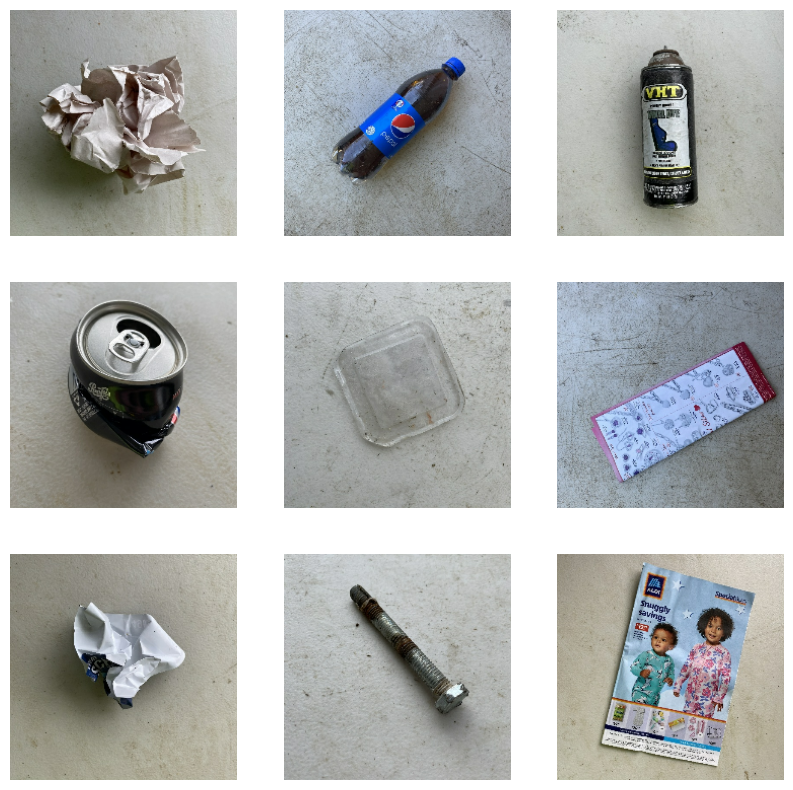

In [7]:
for images, labels in train_data.take(1):
    # Create a 3x3 subplot grid
    plt.figure(figsize=(10, 10))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")
    plt.show()
    break  # Only show first batch

In [8]:
checkpoint_filepath = 'checkpoint.model.keras'
model.load_weights(checkpoint_filepath)

In [11]:
# Training the multi-output model
#!pip install numba --break-system-packages
#from numba import cuda
#device = cuda.get_current_device()
#device.reset()

import torch
import gc
gc.collect()
torch.cuda.empty_cache()
gc.collect()
torch.cuda.empty_cache()


checkpoint_filepath = 'checkpoint.model.keras'
model_checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True)

In [12]:
# Extract labels as 1D integer array
def extract_labels(dataset):
    labels = []
    for _, y in dataset.unbatch():  # Iterate over unbatched dataset
        labels.append(np.argmax(y))
    return np.array(labels).flatten().astype(int)

train_labels = extract_labels(dataset)
# Compute class weights manually
unique_classes, counts = np.unique(train_labels, return_counts=True)
class_weights = (1 / counts) * (len(train_labels) / len(unique_classes))
class_weight_dict = dict(zip(unique_classes, class_weights))
class_weight_dict

2025-04-29 20:25:51.671001: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


{np.int64(0): np.float64(0.9329113924050633),
 np.int64(1): np.float64(1.474),
 np.int64(2): np.float64(0.8002171552660152)}

In [13]:
img_augmentation_layers = [
    layers.RandomRotation(factor=0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomFlip(),
    layers.RandomContrast(factor=0.1),
]

def augment_image(image, labels):
    for layer in img_augmentation_layers:
        image = layer(image)    
    return image, labels


train_data_aug = train_data.shuffle(int(2211*0.8)).map(augment_image, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)#.batch(BATCH_SIZE)
#train_data = train_data.shuffle(2211).map(augment_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).repeat().prefetch(tf.data.AUTOTUNE)
#dataset = dataset.shuffle(2211).map(augment_image, num_parallel_calls=tf.data.AUTOTUNE).batch(16).repeat().prefetch(tf.data.AUTOTUNE)

In [14]:
fit_stats = model.fit(
    #train_data,
    train_data_aug,
    #steps_per_epoch=int((2211*0.8)//BATCH_SIZE),
    #validation_steps=int((221*0.2)//BATCH_SIZE),
    validation_data=val_data,
    #validation_split=0.2,
    epochs=EPOCHS,
    callbacks=[model_checkpoint_callback],
    class_weight=class_weight_dict
)

Epoch 1/100


2025-04-29 20:26:25.780233: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 19268224 bytes after encountering the first element of size 19268224 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
2025-04-29 20:26:25.819690: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 51380224 exceeds 10% of free system memory.
2025-04-29 20:26:25.928397: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 51380224 exceeds 10% of free system memory.
2025-04-29 20:26:25.958691: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 51380224 exceeds 10% of free system memory.
2025-04-29 20:26:26.003907: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 51380224 exceeds 10% of free system memory.
2025-04-29 20:26:26.046459: W external/local_xla/xla/t

56/56 ━━━━━━━━━━━━━━━━━━━━ 41s 602ms/step - accuracy: 0.4863 - loss: 1.0037 - val_accuracy: 0.7149 - val_loss: 0.6826
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 553ms/step - accuracy: 0.7873 - loss: 0.6155 - val_accuracy: 0.7670 - val_loss: 0.5601
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 34s 584ms/step - accuracy: 0.8082 - loss: 0.5283 - val_accuracy: 0.8054 - val_loss: 0.5020
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 34s 583ms/step - accuracy: 0.8357 - loss: 0.4424 - val_accuracy: 0.8145 - val_loss: 0.4543
Epoch 5/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 608ms/step - accuracy: 0.8543 - loss: 0.4029 - val_accuracy: 0.8303 - val_loss: 0.4301
Epoch 6/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 621ms/step - accuracy: 0.8528 - loss: 0.3742 - val_accuracy: 0.8348 - val_loss: 0.4156
Epoch 7/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 622ms/step - accuracy: 0.8493 - loss: 0.3771 - val_accuracy: 0.8507 - val_loss: 0.3941
Epoch 8/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 34s 576ms/step - accuracy: 0.8625 - loss: 0.3507 - val_accuracy

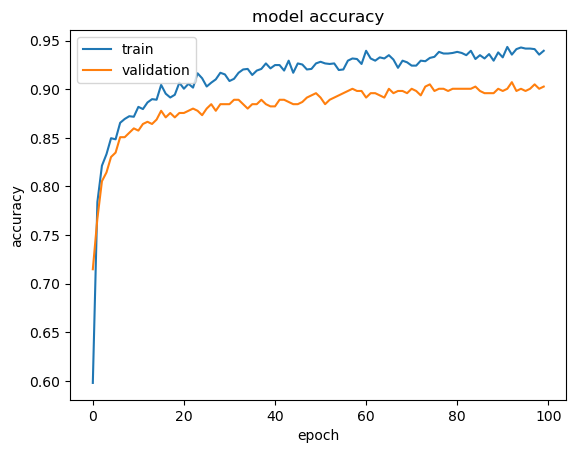

In [15]:
import matplotlib.pyplot as plt

def plot_hist(hist):
    plt.plot(hist.history["accuracy"])
    plt.plot(hist.history["val_accuracy"])
    plt.title("model accuracy")
    plt.ylabel("accuracy")
    plt.xlabel("epoch")
    plt.legend(["train", "validation"], loc="upper left")
    plt.show()


plot_hist(fit_stats)

In [87]:
old_fit = fit_stats

In [18]:
model.save("weights.keras")

In [39]:
img = keras.utils.load_img("dataset/Paper/Paper_50.jpg")
#print(keras.utils.img_to_array(img))
pred = model.predict(tf.expand_dims(img, axis=0))
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


array([[0.0029195 , 0.9771403 , 0.01994009]], dtype=float32)